# Premier League Match Exploration

Explore the raw CSV yourself in this notebook. The first code cell loads the file without cleaning or transforming it.

In [53]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv(
    "data/combined/PremierLeague_2017-2026.csv"
)

#No need to put the columns with betting odds. Just keep the match stats columns. 
wanted_columns = [
    "Date", "HomeTeam", "AwayTeam",
    "FTHG", "FTAG", "FTR",
    "HTHG", "HTAG", "HTR",
    "HS", "AS", "HST", "AST",
    "HC", "AC",
    "HF", "AF",
    "HY", "AY",
    "HR", "AR",
]

#Select only the match stats columns from the dataframe
df = df[wanted_columns].copy()

df

,Date,HomeTeam,AwayTeam,FTHG,FTAG,FTR,HTHG,HTAG,HTR,HS,...,HST,AST,HC,AC,HF,AF,HY,AY,HR,AR
0,11/08/2017,Arsenal,Leicester,4,3,H,2,2,D,27,...,10,3,9,4,9,12,0,1,0,0
1,12/08/2017,Brighton,Man City,0,2,A,0,0,D,6,...,2,4,3,10,6,9,0,2,0,0
2,12/08/2017,Chelsea,Burnley,2,3,A,0,3,A,19,...,6,5,8,5,16,11,3,3,2,0
3,12/08/2017,Crystal Palace,Huddersfield,0,3,A,0,2,A,14,...,4,6,12,9,7,19,1,3,0,0
4,12/08/2017,Everton,Stoke,1,0,H,1,0,H,9,...,4,1,6,7,13,10,1,1,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3415,24/05/2026,Man City,Aston Villa,1,2,A,1,0,H,16,...,3,5,9,4,8,4,1,0,0,0
3416,24/05/2026,Nott'm Forest,Bournemouth,1,1,D,1,0,H,15,...,5,4,6,3,11,7,1,1,0,0
3417,24/05/2026,Sunderland,Chelsea,2,1,H,1,0,H,20,...,2,1,7,7,15,18,3,2,0,0
3418,24/05/2026,Tottenham,Everton,1,0,H,1,0,H,21,...,6,3,6,2,15,12,5,3,0,1


Missing Values


In [54]:
missing_values = df.isna().sum()

missing_values

Date        0
HomeTeam    0
AwayTeam    0
FTHG        0
FTAG        0
FTR         0
HTHG        0
HTAG        0
HTR         0
HS          0
AS          0
HST         0
AST         0
HC          0
AC          0
HF          0
AF          0
HY          0
AY          0
HR          0
AR          0
dtype: int64

Data does not have any missing values.

Want to convert dates to their respective seasonal year.

In [55]:
df["Date"] = pd.to_datetime(df["Date"], format="%d/%m/%Y")

season_start_year = df["Date"].dt.year.where(
    df["Date"].dt.month >= 8,
    df["Date"].dt.year - 1
)

df["Season"] = (
    season_start_year.astype(str).str[-2:]
    + "-"
    + (season_start_year + 1).astype(str).str[-2:]
)

Given a completed match’s statistics, can we classify the result?

Want Full time result as the target. Don't want to include features like half time result and goals as that would heavily correlate or directly give the result.

HS = Home Team Shots

AS = Away Team Shots

HST = Home Team Shots on Target

AST = Away Team Shots on Target

HC = Home Team Corners

AC = Away Team Corners

HF = Home Team Fouls Committed

AF = Away Team Fouls Committed

HY = Home Team Yellow Cards

AY = Away Team Yellow Cards

HR = Home Team Red Cards

AR = Away Team Red Cards

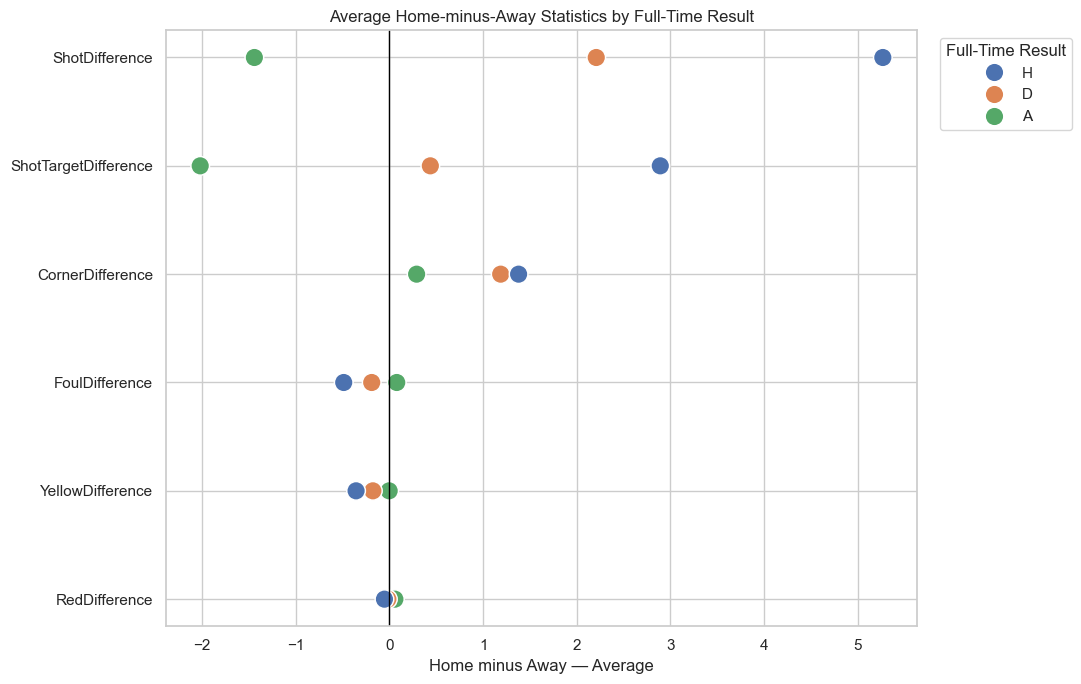

In [56]:
match_stats = [
    "HS", "AS", "HST", "AST",
    "HC", "AC", "HF", "AF",
    "HY", "AY", "HR", "AR"
]

#Want the relative stats for each category (difference between home and away team.)
df["ShotDifference"] = df["HS"] - df["AS"]
df["ShotTargetDifference"] = df["HST"] - df["AST"]
df["CornerDifference"] = df["HC"] - df["AC"]
df["FoulDifference"] = df["HF"] - df["AF"]
df["YellowDifference"] = df["HY"] - df["AY"]
df["RedDifference"] = df["HR"] - df["AR"]

difference_columns = [
    "ShotDifference",
    "ShotTargetDifference",
    "CornerDifference",
    "FoulDifference",
    "YellowDifference",
    "RedDifference",
]


#A visualization of the average home-away difference stats for each result.
summary = (
    df.groupby("FTR")[difference_columns]
      .mean()
      .reset_index()
      .melt(
          id_vars="FTR",
          var_name="Statistic",
          value_name="Mean Difference"
      )
)

sns.set_theme(style="whitegrid")

plt.figure(figsize=(11, 7))

sns.scatterplot(
    data=summary,
    x="Mean Difference",
    y="Statistic",
    hue="FTR",
    hue_order=["H", "D", "A"],
    s=180
)

plt.axvline(0, color="black", linewidth=1)
plt.title("Average Home-minus-Away Statistics by Full-Time Result")
plt.xlabel("Home minus Away — Average")
plt.ylabel("")
plt.legend(title="Full-Time Result", bbox_to_anchor=(1.02, 1))
plt.tight_layout()
plt.show()

Season by Season Analysis

   Season FTR  ShotDifference  ShotTargetDifference  CornerDifference  \
0   17-18   A       -2.333333             -2.351852         -0.018519   
1   17-18   D        3.575758              0.585859          2.050505   
2   17-18   H        5.410405              3.028902          1.468208   
3   18-19   A       -1.015625             -1.812500          0.226562   
4   18-19   D        3.647887              0.478873          1.732394   
5   18-19   H        5.563536              2.878453          1.580110   
6   19-20   A       -1.793103             -2.620690          0.077586   
7   19-20   D        1.804348              0.532609          1.043478   
8   19-20   H        4.494186              2.720930          1.250000   
9   20-21   A       -1.366013             -1.843137          0.797386   
10  20-21   D        1.722892              0.433735          1.120482   
11  20-21   H        4.291667              2.923611          0.951389   
12  21-22   A       -3.038760             -2.620155

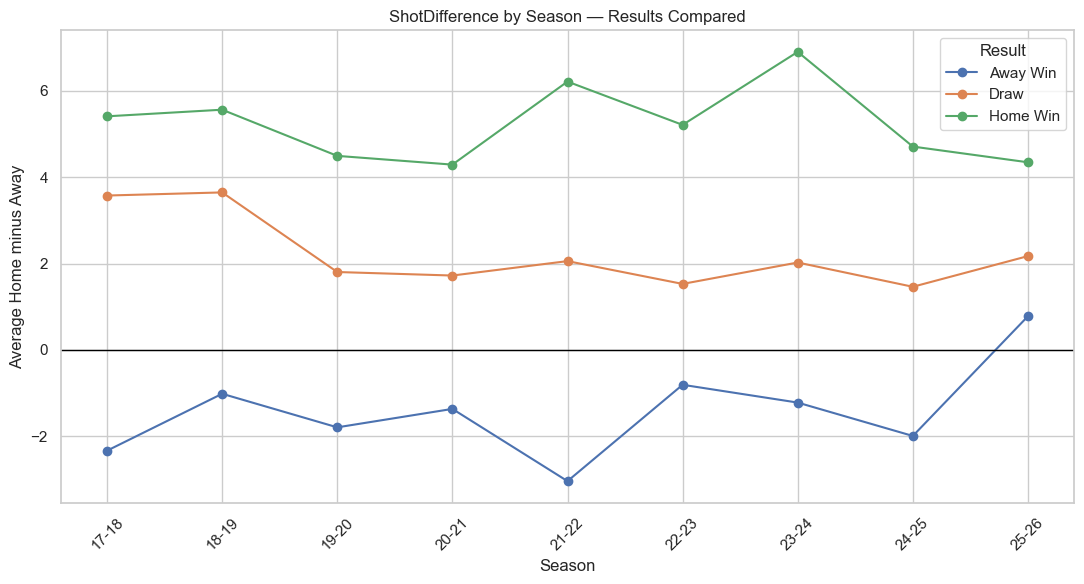

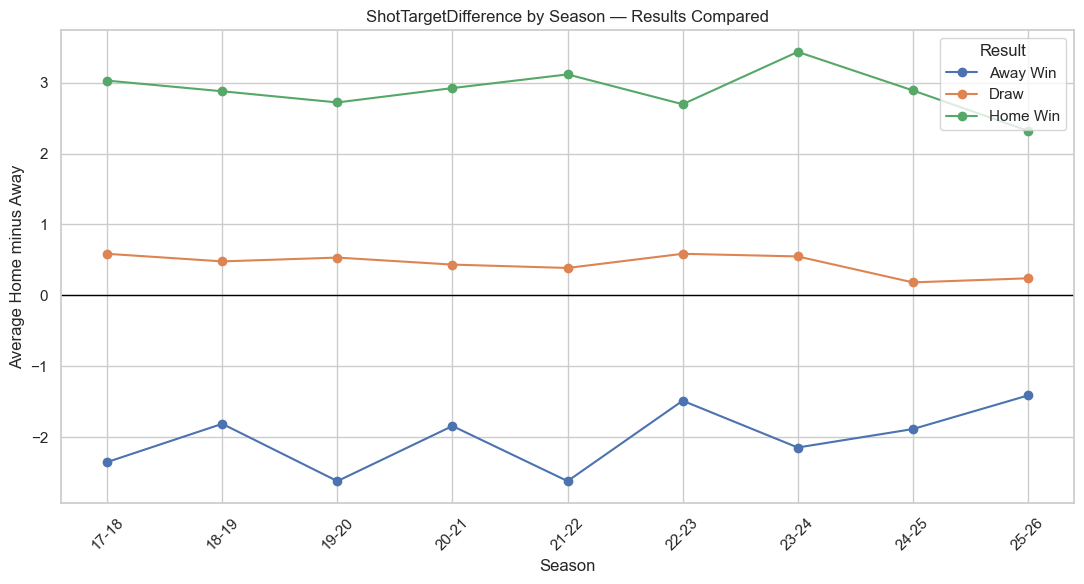

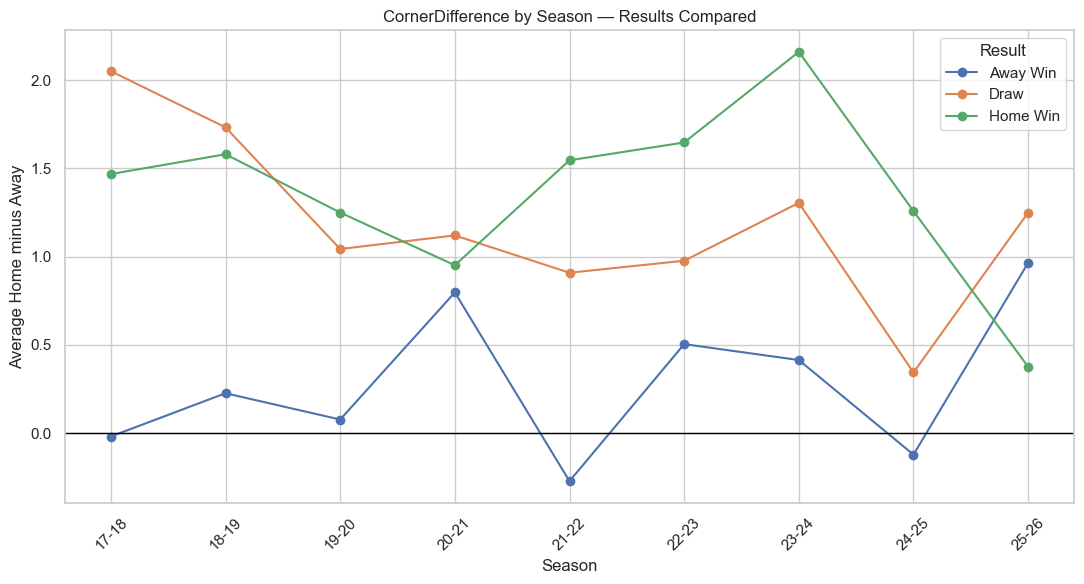

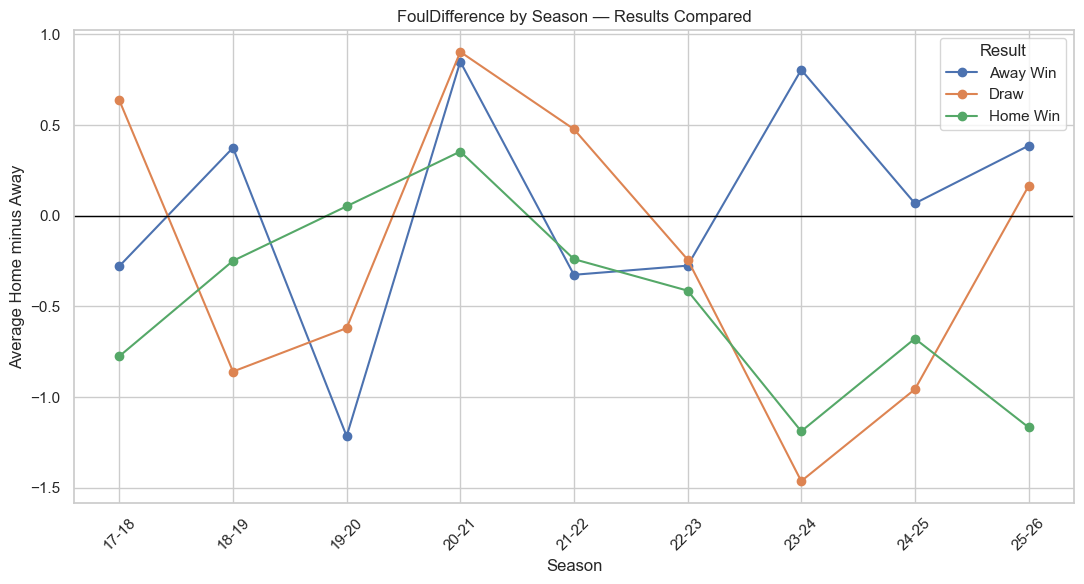

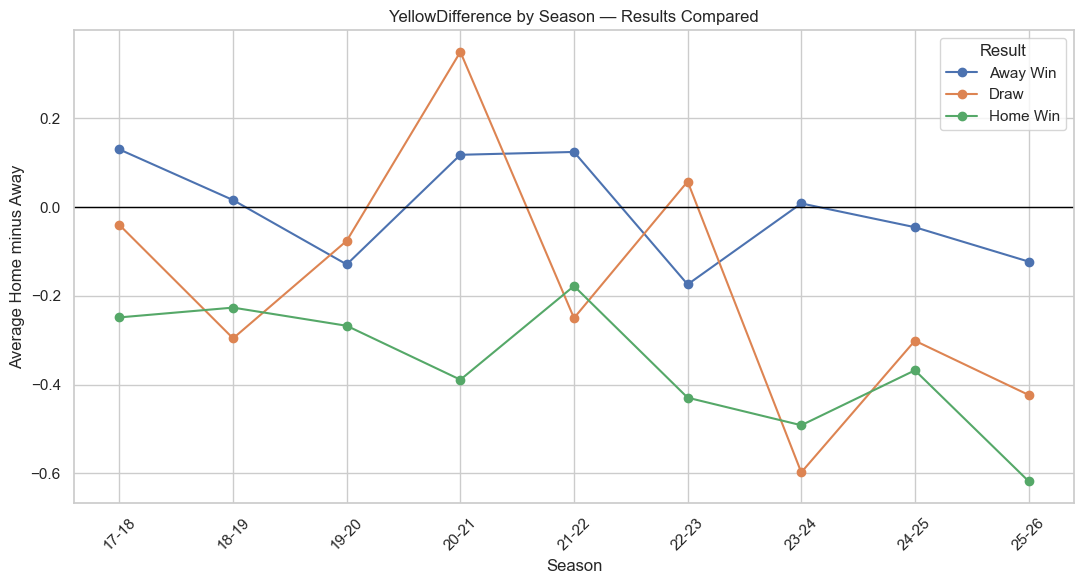

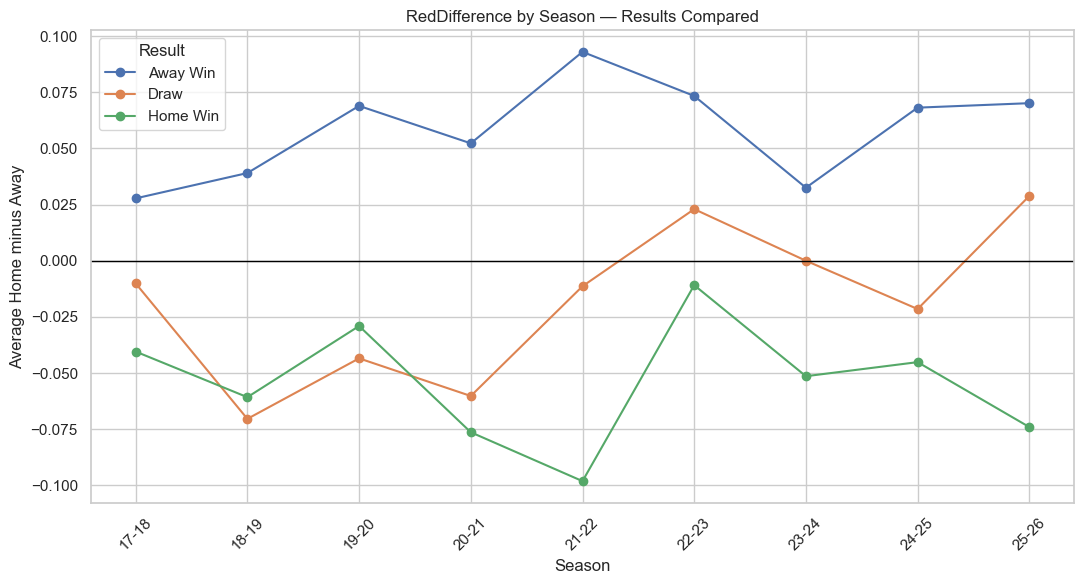

In [57]:
season_result_stats = (
    df.groupby(["Season", "FTR"])[difference_columns]
      .mean()
      .reset_index()
)

print(season_result_stats)

def plot_season_stat_comparison(statistic):
    result_names = {"A": "Away Win", "D": "Draw", "H": "Home Win"}

    chart_data = season_result_stats.pivot(
        index="Season",
        columns="FTR",
        values=statistic
    )

    chart_data = chart_data.rename(columns=result_names)

    chart_data.plot(
        marker="o",
        figsize=(11, 6)
    )

    plt.axhline(0, color="black", linewidth=1)
    plt.title(f"{statistic} by Season — Results Compared")
    plt.xlabel("Season")
    plt.ylabel("Average Home minus Away")
    plt.xticks(rotation=45)
    plt.legend(title="Result")
    plt.tight_layout()
    plt.show()

for stat in difference_columns:
    plot_season_stat_comparison(stat)

Want to see how correlated the relative stats are to the full time results. For example, if the value is high as in Shot Target Difference, then it has a high positive relation to the home team winning.

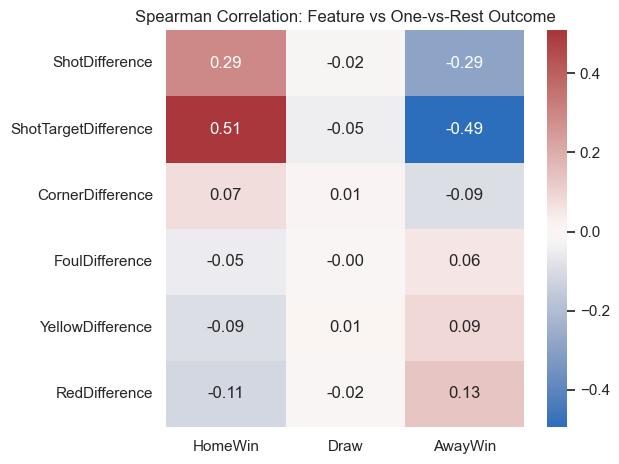

In [58]:
binary_targets = pd.DataFrame({
    "HomeWin": df["FTR"].eq("H").astype(int),
    "Draw": df["FTR"].eq("D").astype(int),
    "AwayWin": df["FTR"].eq("A").astype(int),
})

correlation_table = pd.concat(
    [df[difference_columns], binary_targets],
    axis=1
).corr(method="spearman")

one_vs_rest = correlation_table.loc[difference_columns, binary_targets.columns]

sns.heatmap(
    one_vs_rest,
    annot=True,
    fmt=".2f",
    cmap="vlag",
    center=0
)

plt.title("Spearman Correlation: Feature vs One-vs-Rest Outcome")
plt.tight_layout()
plt.show()

Check if this correlation is stable throughout the seasons.

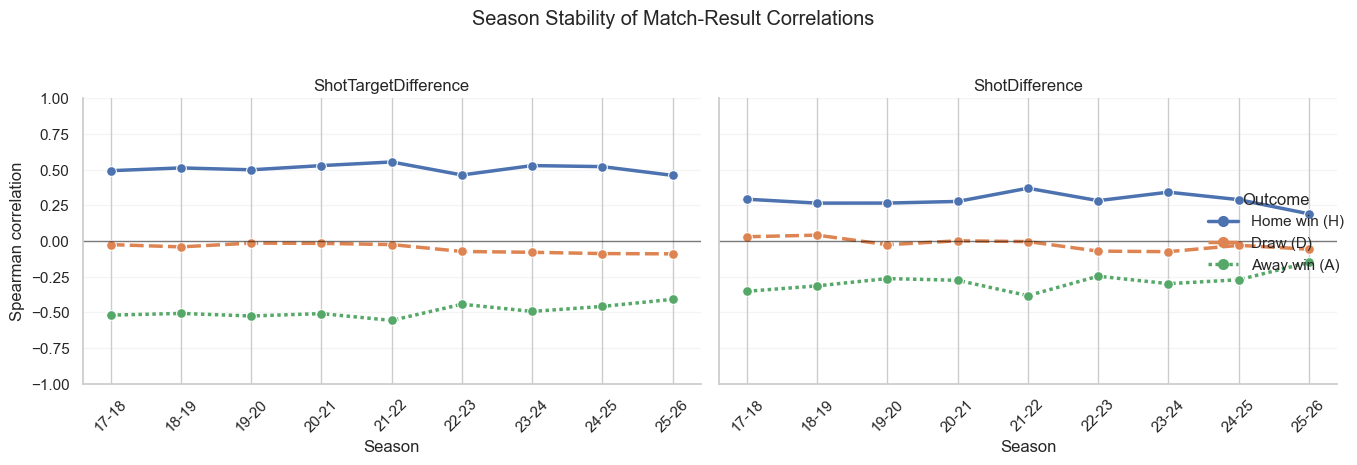

In [ ]:
season_correlation = (
    df.groupby("Season")[["ShotTargetDifference", "ShotDifference", "FTR"]]
      .apply(lambda group: group
             .assign(HomeWin=group["FTR"].eq("H").astype(int),
                     Draw=group["FTR"].eq("D").astype(int),
                     AwayWin=group["FTR"].eq("A").astype(int))
             [["ShotTargetDifference", "ShotDifference",
               "HomeWin", "Draw", "AwayWin"]]
             .corr(method="spearman")
             .loc[["ShotTargetDifference", "ShotDifference"],
                  ["HomeWin", "Draw", "AwayWin"]])
)

print(season_correlation)

season_corr_long = (
    season_correlation
    .rename_axis(index=["Season", "Statistic"])
    .reset_index()
    .melt(
        id_vars=["Season", "Statistic"],
        value_vars=["HomeWin", "Draw", "AwayWin"],
        var_name="Outcome",
        value_name="Correlation"
    )
)

outcome_names = {
    "HomeWin": "Home win (H)",
    "Draw": "Draw (D)",
    "AwayWin": "Away win (A)"
}
season_corr_long["Outcome"] = season_corr_long["Outcome"].map(outcome_names)

g = sns.relplot(
    data=season_corr_long,
    x="Season",
    y="Correlation",
    hue="Outcome",
    style="Outcome",
    col="Statistic",
    kind="line",
    marker="o",
    height=4.5,
    aspect=1.35,
    linewidth=2.5,
    markersize=7,
    facet_kws={"sharey": True, "sharex": True}
)

for ax in g.axes.flat:
    ax.axhline(0, color="black", linewidth=1, alpha=0.5)
    ax.set_ylim(-1, 1)
    ax.set_xlabel("Season")
    ax.set_ylabel("Spearman correlation")
    ax.grid(axis="y", alpha=0.2)
    ax.tick_params(axis="x", rotation=45)

g.set_titles("{col_name}")
g.figure.suptitle("Season Stability of Match-Result Correlations", y=1.03)
g.figure.tight_layout()
plt.show()

Basically, we see that these correlations are stable throughout the seasons. 

Want to check distribution of results with respect to shots on target. 

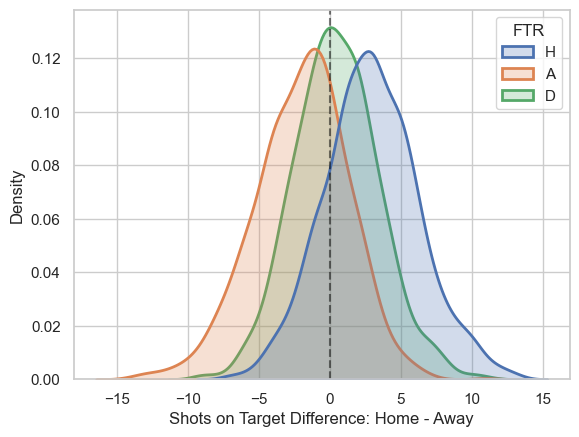

In [ ]:
sns.kdeplot(
    data=df,
    x="ShotTargetDifference",
    hue="FTR",
    common_norm=False,
    fill=True,
    alpha=0.25,
    linewidth=2
)

plt.axvline(0, color="black", linestyle="--", alpha=0.5)
plt.xlabel("Shots on Target Difference: Home - Away")
plt.ylabel("Density")
plt.show()